# A04 · 04 · A06 hypothesis panel
Targeted look at the A06 signature: ER chaperones induced, canonical UPR sensors flat, NF-κB/chemokines, candidate regulators (AR, MIST1/BHLHA15). **This is the core hypothesis test.**

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))   # a04_common.py next to notebooks
import a04_common as ac
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
print('project root:', ac.PROJ)


project root: /storage/users/job37yv/Projects/DECIDE_A04_CdiffOrganoid_Butyrate


In [2]:
counts = ac.load_counts(); meta = ac.load_meta(); counts = counts[meta.index]
id2sym, sym2id = ac.load_symbol_map(); counts_f = ac.prefilter(counts)
ln = ac.lognorm_cpm(counts_f)
order = meta.sort_values('group').index

## Panel heatmap (z-scored log-CPM, samples grouped)

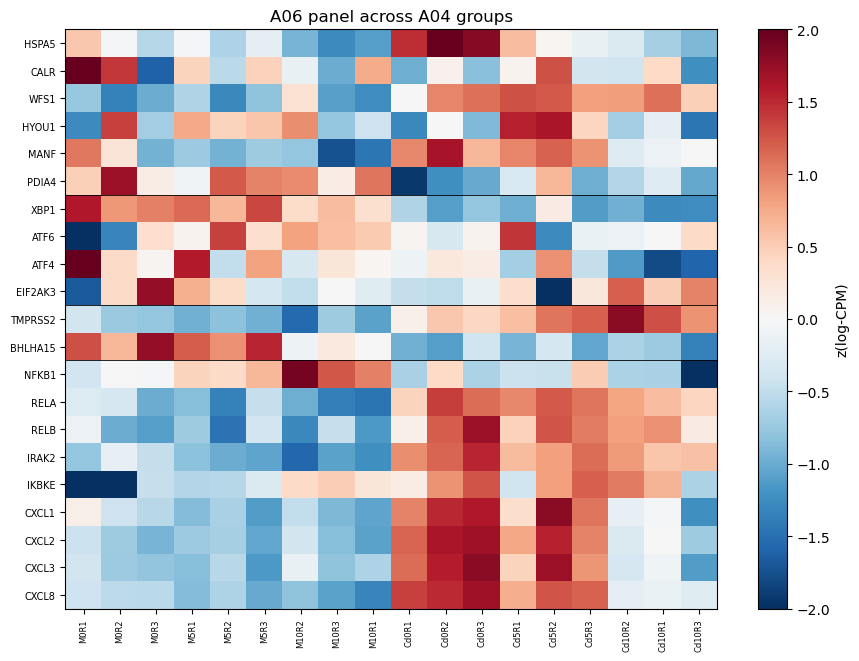

In [3]:
genes, labels, sep = [], [], []
for grp, gs in ac.PANELS.items():
    for g in gs:
        gid = sym2id.get(g)
        if gid in ln.index: genes.append(gid); labels.append(g)
    sep.append(len(genes))
z = ln.loc[genes, order]; z = z.sub(z.mean(1),0).div(z.std(1).replace(0,1),0)
fig, ax = plt.subplots(figsize=(9, max(3,.32*len(genes))))
im = ax.imshow(z.values, aspect='auto', cmap='RdBu_r', vmin=-2, vmax=2)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=90, fontsize=6)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=7)
for s in sep[:-1]: ax.axhline(s-0.5, c='k', lw=.6)
fig.colorbar(im, ax=ax, label='z(log-CPM)'); ax.set_title('A06 panel across A04 groups')
plt.tight_layout(); plt.savefig(ac.FIG/'panel_A06_heatmap.png', dpi=130); plt.show()

## Dose trajectories: chaperones vs sensors vs CXCL8
Mean expression vs butyrate, Mock (blue) vs Cd (red). Prediction: chaperones rise, sensors flat, CXCL8 falls with butyrate in Cd.

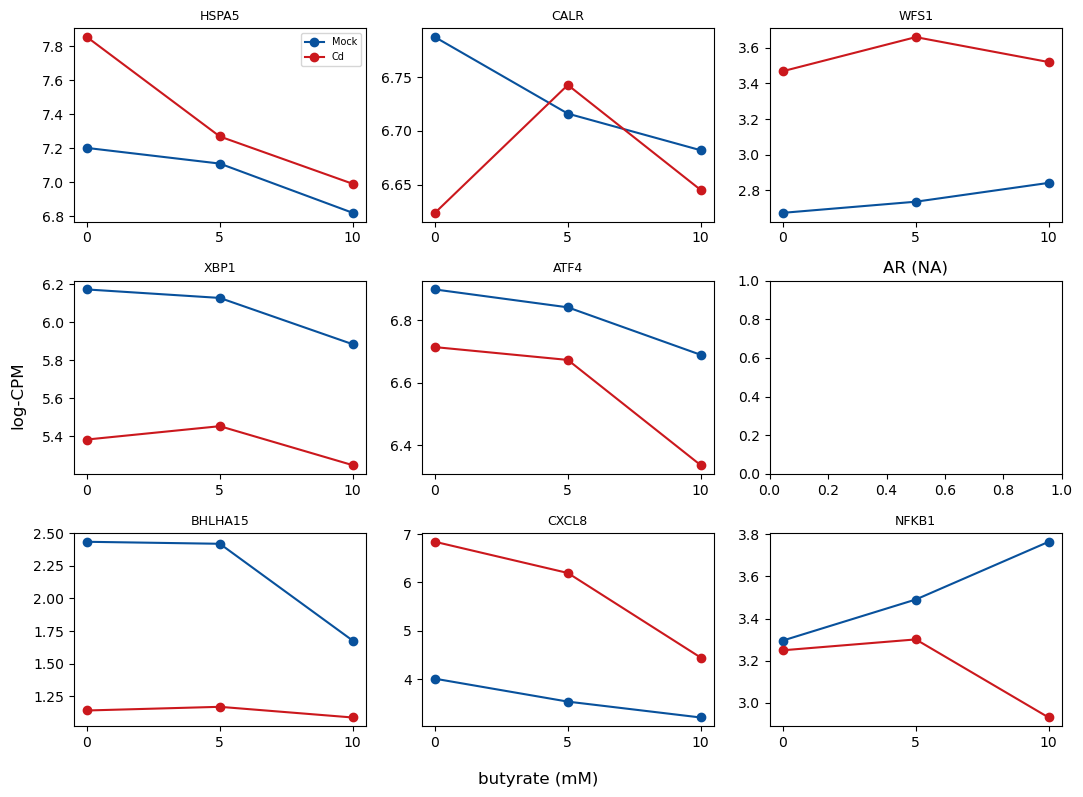

In [4]:
def traj(gene, ax):
    gid = sym2id.get(gene)
    if gid not in ln.index: ax.set_title(f'{gene} (NA)'); return
    df = ln.loc[gid].to_frame('e').join(meta)
    for inf,c in [('Mock','#08519c'),('Cd','#cb181d')]:
        m = df[df.infection==inf].groupby('butyrate')['e'].mean()
        ax.plot(m.index, m.values, '-o', c=c, label=inf)
    ax.set_title(gene, fontsize=9); ax.set_xticks([0,5,10])
genes_show = ['HSPA5','CALR','WFS1','XBP1','ATF4','AR','BHLHA15','CXCL8','NFKB1']
fig, axes = plt.subplots(3,3, figsize=(11,8)); 
for ax,g in zip(axes.ravel(), genes_show): traj(g, ax)
axes.ravel()[0].legend(fontsize=7); fig.supxlabel('butyrate (mM)'); fig.supylabel('log-CPM')
plt.tight_layout(); plt.show()

## Quick verdict helper (fill once DE tables exist)

In [5]:
# uses DE_*.csv from notebook 03
def lfc(name, gene):
    r = pd.read_csv(ac.TAB/f'DE_{name}.csv', index_col=0)
    gid = sym2id.get(gene); return r.loc[gid,'log2FoldChange'] if gid in r.index else np.nan
try:
    print('Chaperone HSPA5 butyrate 10v0 (Cd):', round(lfc('Butyrate_10v0_Cd','HSPA5'),2))
    print('Sensor   XBP1  butyrate 10v0 (Cd):', round(lfc('Butyrate_10v0_Cd','XBP1'),2))
    print('Chemokine CXCL8 butyrate 10v0 (Cd):', round(lfc('Butyrate_10v0_Cd','CXCL8'),2))
except FileNotFoundError:
    print('run notebook 03 first to generate DE_*.csv')

Chaperone HSPA5 butyrate 10v0 (Cd): -1.49
Sensor   XBP1  butyrate 10v0 (Cd): -0.44
Chemokine CXCL8 butyrate 10v0 (Cd): -3.73
